# 13F stock recommendations

- Implicit ALS on position size, vs recommending the most widely held names
- Then which stocks sit near each other in the factor space

In [ ]:
%load_ext autoreload
%autoreload 2

import logging
import os
import sys

import matplotlib.pyplot as plt
import pyspark.sql.functions as F
import seaborn as sns

In [ ]:
# Find helpers_root from the project directory or the repo root.
_path = os.getcwd()
while not os.path.isdir(os.path.join(_path, "helpers_root", "helpers")):
    _parent = os.path.dirname(_path)
    if _parent == _path:
        break
    _path = _parent
sys.path.insert(0, os.path.join(_path, "helpers_root"))

import helpers.hnotebook as hnotebook

import mllib_utils as utils

hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > C:\Users\Sawyer Byrd\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\ipykernel_launcher.py --f="c:\Users\Sawyer Byrd\AppData\Roaming\jupyter\runtime\kernel-v34e153cc86ce00d3e8b0919540da72b015a9d0468.json"


## Ratings

- $\log(1 + \mathrm{value})$, value in dollars
- An open is a CUSIP held next quarter and not this quarter
- `cold_share`: that CUSIP is missing from the training quarter, so ALS
  has no item factor and it is left out of the metric
- `median_positions` is why the top 10 skips the current book

In [ ]:
holdings = utils.ingest_holdings(utils.project_data_dir())
# one row per quarter. the matrix is large
by_quarter = holdings.groupBy(
    F.col("report_period").cast("string").alias("quarter")
).agg(
    F.count("*").alias("rows"),
    F.countDistinct("cik").alias("managers"),
    F.countDistinct("cusip").alias("cusips"),
)
display(by_quarter.orderBy("quarter").toPandas())
# log so a $1B stake doesn't drown a $1M one
ratings = holdings.withColumn("rating", F.log1p("value")).persist()
ratings.count()
display(utils.open_summary(ratings))

Reading holdings Parquet 'c:\Users\Sawyer Byrd\Desktop\School\MSML610\class_project\msml610\Fall2026\projects\UmdTask656_MSML610_Fall2026_MLlib_Stock_Recommendations_for_Institutional_Investors\data\holdings'
Holdings rows=6283352 managers=2000 cusips=5000 periods=4


,quarter,rows,managers,cusips
0,2025-09-30,1485421,1902,4930
1,2025-12-31,1562323,1969,4957
2,2026-03-31,1598205,1973,4938
3,2026-06-30,1637403,1956,4916


,train_period,test_period,median_positions,n_opens,n_cold_opens,cold_share
0,2025-09-30,2025-12-31,472,190375,2545,0.0134
1,2025-12-31,2026-03-31,491,203305,1818,0.0089
2,2026-03-31,2026-06-30,499,217277,5473,0.0252


## ALS vs most-held

- Tune `rank`, `regParam`, and `alpha` on the earliest pair only
- `tuned` is that pair. `held_out` is the later ones
- Both lists drop stocks already held, then keep 10
- Small / mid / large are terciles of training-quarter dollars

In [ ]:
# 2 x 2 x 2 = 8 models. this is the slow cell
grid = utils.tune_als(
    ratings, ranks=[8, 16], reg_params=[0.05, 0.1], alphas=[1.0, 40.0]
)
display(grid)
best = grid.iloc[0]
metrics, model, items = utils.score_quarters(
    ratings, int(best["rank"]), float(best["reg_param"]), float(best["alpha"])
)
overall = metrics[metrics["bucket"] == "all"]
display(overall.drop(columns=["rank", "reg_param", "alpha"]))
by_size = metrics[metrics["bucket"] != "all"]
display(
    by_size[
        [
            "test_period",
            "role",
            "bucket",
            "model",
            "precision_at_10",
            "ndcg_at_10",
            "n_managers",
            "cold_share",
        ]
    ]
)

,train_period,test_period,model,bucket,precision_at_10,ndcg_at_10,n_managers,cold_share,rank,reg_param,alpha
0,2025-09-30,2025-12-31,ALS,all,0.2010,0.2083,1887,0.0134,8,0.10,1.0
1,2025-09-30,2025-12-31,ALS,all,0.1996,0.2061,1887,0.0134,8,0.05,1.0
2,2025-09-30,2025-12-31,ALS,all,0.1919,0.1943,1887,0.0134,16,0.10,1.0
3,2025-09-30,2025-12-31,ALS,all,0.1869,0.1892,1887,0.0134,16,0.05,1.0
4,2025-09-30,2025-12-31,ALS,all,0.0495,0.0487,1887,0.0134,8,0.10,40.0
5,2025-09-30,2025-12-31,ALS,all,0.0495,0.0477,1887,0.0134,8,0.05,40.0
6,2025-09-30,2025-12-31,ALS,all,0.0437,0.0426,1887,0.0134,16,0.10,40.0
7,2025-09-30,2025-12-31,ALS,all,0.0421,0.0407,1887,0.0134,16,0.05,40.0


,train_period,test_period,model,bucket,precision_at_10,ndcg_at_10,n_managers,cold_share,role
0,2025-09-30,2025-12-31,ALS,all,0.2010,0.2083,1887,0.0134,tuned
4,2025-09-30,2025-12-31,most held,all,0.2253,0.2395,1887,0.0134,tuned
8,2025-12-31,2026-03-31,ALS,all,0.2121,0.2198,1946,0.0089,held_out
12,2025-12-31,2026-03-31,most held,all,0.2359,0.2496,1946,0.0089,held_out
16,2026-03-31,2026-06-30,ALS,all,0.2223,0.2323,1934,0.0252,held_out
20,2026-03-31,2026-06-30,most held,all,0.2472,0.2653,1934,0.0252,held_out


,test_period,role,bucket,model,precision_at_10,ndcg_at_10,n_managers,cold_share
1,2025-12-31,tuned,small,ALS,0.1863,0.1940,626,0.0134
2,2025-12-31,tuned,mid,ALS,0.2000,0.2111,632,0.0134
3,2025-12-31,tuned,large,ALS,0.2167,0.2197,629,0.0134
5,2025-12-31,tuned,small,most held,0.2142,0.2286,626,0.0134
6,2025-12-31,tuned,mid,most held,0.2427,0.2595,632,0.0134
7,2025-12-31,tuned,large,most held,0.2189,0.2301,629,0.0134
9,2026-03-31,held_out,small,ALS,0.1935,0.2018,648,0.0089
10,2026-03-31,held_out,mid,ALS,0.2061,0.2148,652,0.0089
11,2026-03-31,held_out,large,ALS,0.2367,0.2429,646,0.0089
13,2026-03-31,held_out,small,most held,0.2188,0.2349,648,0.0089


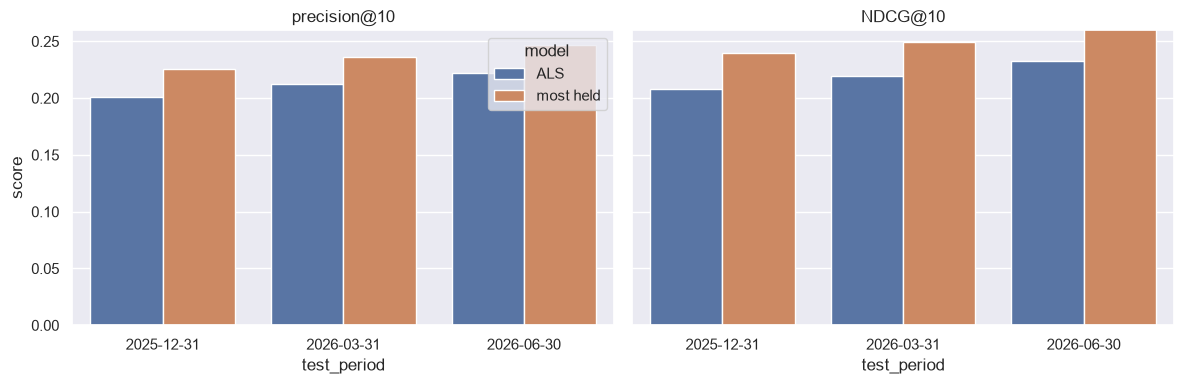

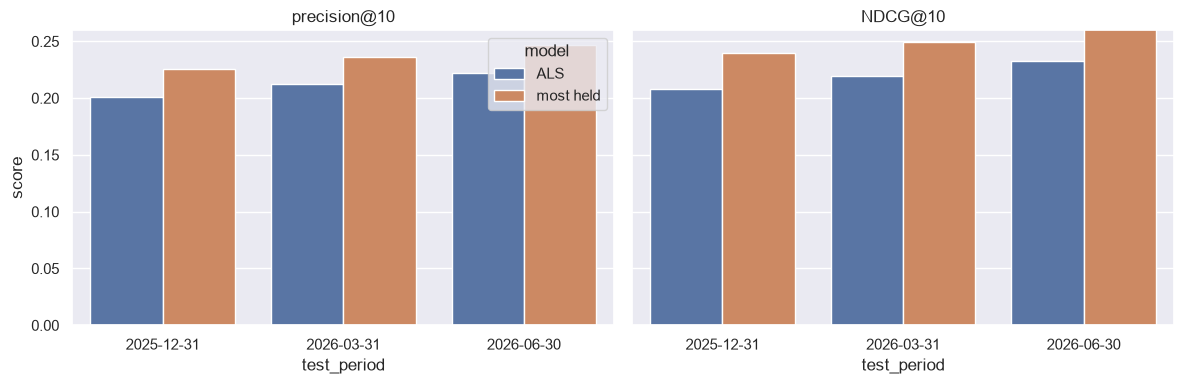

In [ ]:
# taller bar wins. first quarter on the x-axis is the one we tuned on
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
panels = (("precision_at_10", "precision@10"), ("ndcg_at_10", "NDCG@10"))
for ax, (column, title) in zip(axes, panels):
    sns.barplot(
        data=overall,
        x="test_period",
        y=column,
        hue="model",
        hue_order=["ALS", "most held"],
        ax=ax,
    )
    ax.set_title(title)
    ax.set_ylim(0, None)
axes[0].set_ylabel("score")
if axes[1].get_legend() is not None:
    axes[1].get_legend().remove()
fig.tight_layout()
display(fig)

## Neighbors and clusters

- Cosine similarity of the latest quarter's item factors
- `KMeans` with 8 clusters. `examples` is the five most-held names

,seed,rank,neighbor,cosine
0,AAPL,1,BROADCOM INC,1.000
1,AAPL,2,ALPHABET INC,1.000
2,AAPL,3,ALPHABET INC,1.000
3,AAPL,4,VISA INC,0.999
4,AAPL,5,WALMART INC,0.999
5,MSFT,1,ALPHABET INC,1.000
6,MSFT,2,AMAZON COM INC,1.000
7,MSFT,3,META PLATFORMS INC,1.000
8,MSFT,4,BROADCOM INC,1.000
9,MSFT,5,NVIDIA CORPORATION,0.999


,cluster,n,examples
0,0,486,MP MATERIALS CORP; JOBY AVIATION INC; TRANSOCE...
1,1,671,ITT INC; WOODWARD INC; EXELIXIS INC; US FOODS ...
2,2,604,JACKSON FINANCIAL INC; SABRA HEALTH CARE REIT ...
3,3,307,SONY GROUP CORP; TOYOTA MOTOR CORP; BHP BILLIT...
4,4,692,FS KKR CAP CORP; FIRST TR EXCHANGE TRADED FD; ...
5,5,610,VANGUARD INDEX FDS; VANGUARD SPECIALIZED FUNDS...
6,6,766,MICROSOFT CORP; NVIDIA CORPORATION; AMAZON COM...
7,7,802,ZYMEWORKS INC; AXOGEN INC; MATIV HOLDINGS INC;...


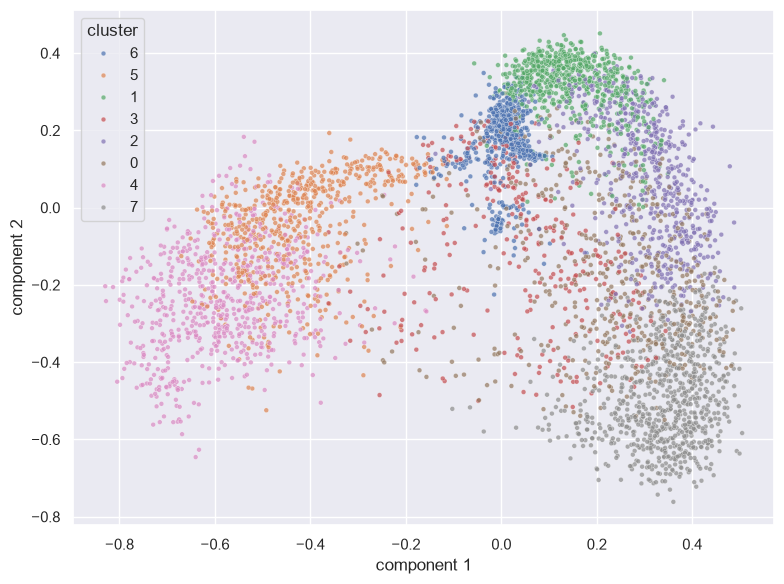

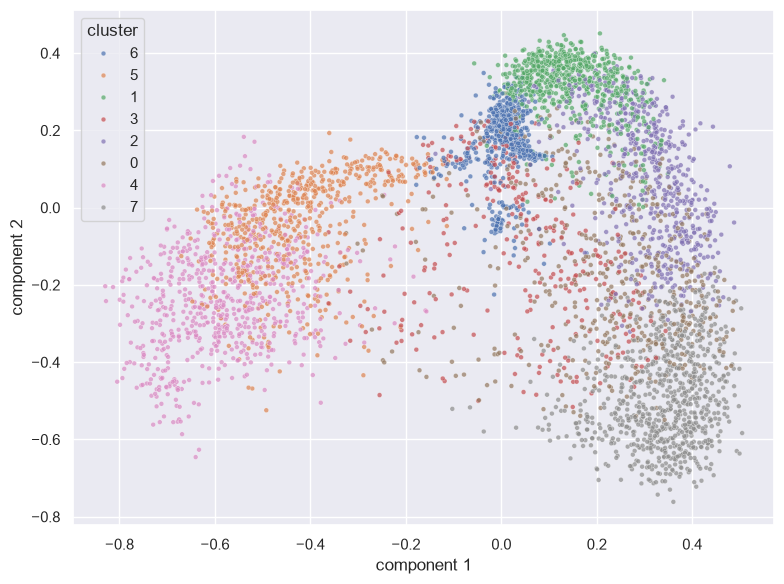

In [ ]:
display(utils.item_neighbors(model, items, utils.KNOWN_STOCKS))
summary, points = utils.cluster_items(model, items, k=8)
display(summary)
# 2D view of the factors, color is the cluster
plot_df = points.copy()
plot_df["cluster"] = plot_df["cluster"].astype(str)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=plot_df, x="x", y="y", hue="cluster", s=12, alpha=0.7, ax=ax
)
ax.set_xlabel("component 1")
ax.set_ylabel("component 2")
fig.tight_layout()
display(fig)